# FTW Pretrained Model — Agricultural Field Boundary Detection

This notebook runs a pretrained Fields of the World (FTW) model on a small area of US farmland, creates field polygons, plots them over satellite imagery, and exports GeoJSON.

No training or manual polygon drawing is required. The output is a prediction of agricultural field boundaries, **not an authoritative legal parcel map**.

**Before running:** follow `README_Windows_Setup.md` to install FTW in a dedicated Python environment and select the **Python (FTW)** Jupyter kernel.

## 1. Check the environment

In [7]:
from pathlib import Path
import subprocess

REPO_DIR = Path.home() / "ftw-baselines"

result = subprocess.run(
    ["uv", "run", "ftw", "inference", "all", "--help"],
    cwd=str(REPO_DIR),
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)

Usage: ftw inference all [OPTIONS]

  Run all inference commands from crop calendar scene selection,then download,
  inference and polygonize.

Options:
  -o, --out PATH                  Directory to save downloaded inference
                                  imagery, and inference output to  [required]
  -m, --model MODEL_OR_CHECKPOINT
                                  Short model name from the registry OR path
                                  to a checkpoint file (.ckpt).  [required]
  --year INTEGER RANGE            Year to run model inference over
                                  [2015<=x<=2026; required]
  --bbox TEXT                     Bounding box to use for the download in the
                                  format 'minx,miny,maxx,maxy'
  -ccx, --cloud_cover_max INTEGER RANGE
                                  Maximum percentage of cloud cover allowed in
                                  the Sentinel-2 scene  [default: 20;
                                  0<=x<=100]
  -b, 

In [8]:
from pathlib import Path
import subprocess

REPO_DIR = Path.home() / "ftw-baselines"
OUTPUT_DIR = REPO_DIR / "ftw_output"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

command = [
    "uv", "run", "ftw", "inference", "all",
    "--bbox", "-93.7,41.9,-93.5,42.1",
    "--year", "2025",
    "--out", str(OUTPUT_DIR),
    "--model", "FTW_PRUE_EFNET_B5_CCBY",
    "--gpu", "-1",
    "--overwrite"
]

# Lowa - -93.7,41.9,-93.5,42.1
# California - -121.6,38.5,-121.4,38.7
# Bengaluru - 77.5,12.9,77.7,13.1

print("Starting FTW inference...")
print("Output folder:", OUTPUT_DIR)

result = subprocess.run(
    command,
    cwd=str(REPO_DIR),
    text=True
)

if result.returncode == 0:
    print("\nInference completed!")
else:
    print("\nInference failed. Check the error messages above.")

Starting FTW inference...
Output folder: C:\Users\ABCOM\ftw-baselines\ftw_output

Inference completed!


In [9]:
from pathlib import Path

OUTPUT_DIR = Path.home() / "ftw-baselines" / "ftw_output"

files = [p for p in OUTPUT_DIR.rglob("*") if p.is_file()]

if files:
    print(f"Found {len(files)} files:\n")
    for file in files:
        print(f"{file.name} | {file.stat().st_size / 1024:.1f} KB")
else:
    print("No files found in the output folder yet.")

Found 5 files:

enriched_field_data.csv | 236.8 KB
inference_data.tif | 45373.2 KB
inference_output.tif | 171.3 KB
polygons.parquet | 182.9 KB
satellite_fields_overlay.png | 12681.0 KB


Image dimensions (bands, height, width): (8, 2233, 1673)
Number of bands: 8
Coordinate system: EPSG:32615
Bounds: BoundingBox(left=441930.0, bottom=4638790.0, right=458660.0, top=4661120.0)
Data type: ('uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16')


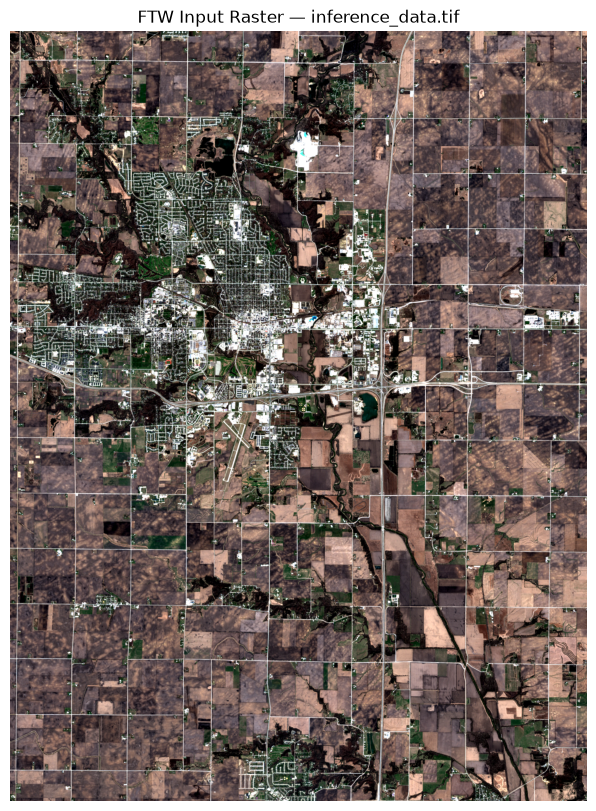

In [10]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Input file path
input_file = Path(
    r"C:\Users\ABCOM\ftw-baselines\ftw_output\inference_data.tif"
)

# Read the raster
with rasterio.open(input_file) as src:
    image = src.read()
    print("Image dimensions (bands, height, width):", image.shape)
    print("Number of bands:", src.count)
    print("Coordinate system:", src.crs)
    print("Bounds:", src.bounds)
    print("Data type:", src.dtypes)

# Display the image
if image.shape[0] >= 3:
    rgb = np.moveaxis(image[:3], 0, -1)

    # Normalize values for visualization
    rgb = rgb.astype(np.float32)
    for i in range(3):
        band = rgb[:, :, i]
        low, high = np.nanpercentile(band, [2, 98])
        if high > low:
            rgb[:, :, i] = np.clip((band - low) / (high - low), 0, 1)

    plt.figure(figsize=(12, 10))
    plt.imshow(rgb)
    plt.title("FTW Input Raster — inference_data.tif")
    plt.axis("off")
    plt.show()
else:
    plt.figure(figsize=(12, 10))
    plt.imshow(image[0], cmap="gray")
    plt.title("FTW Input Raster — Band 1")
    plt.axis("off")
    plt.show()

Shape: (1, 2233, 1673)
Bands: 1
Data type: ('uint8',)
CRS: EPSG:32615
Unique values: [0 1 2]


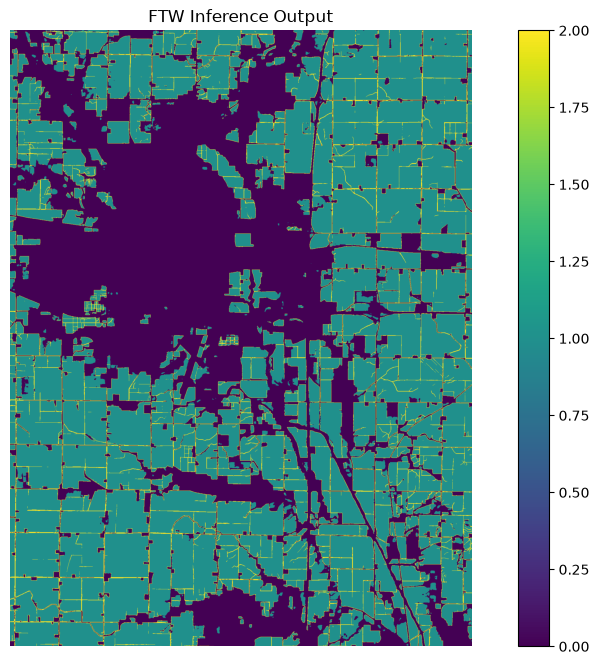

In [11]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

output_file = r"C:\Users\ABCOM\ftw-baselines\ftw_output\inference_output.tif"

with rasterio.open(output_file) as src:
    prediction = src.read()

    print("Shape:", prediction.shape)
    print("Bands:", src.count)
    print("Data type:", src.dtypes)
    print("CRS:", src.crs)
    print("Unique values:", np.unique(prediction[0])[:30])

plt.figure(figsize=(12, 8))
plt.imshow(prediction[0], cmap="viridis")
plt.title("FTW Inference Output")
plt.colorbar()
plt.axis("off")
plt.show()

In [12]:
import geopandas as gpd
import pandas as pd
from pathlib import Path

# Update this path if your output folder is different
output_dir = Path(r"C:\Users\ABCOM\ftw-baselines\ftw_output")

polygon_file = output_dir / "polygons.parquet"

gdf = gpd.read_parquet(polygon_file)

print("Number of polygons:", len(gdf))
print("CRS:", gdf.crs)
print("Columns:", gdf.columns.tolist())

display(gdf.head())

Number of polygons: 1118
CRS: {"$schema": "https://proj.org/schemas/v0.7/projjson.schema.json", "type": "ProjectedCRS", "name": "WGS 84 / UTM zone 15N", "base_crs": {"type": "GeographicCRS", "name": "WGS 84", "datum_ensemble": {"name": "World Geodetic System 1984 ensemble", "members": [{"name": "World Geodetic System 1984 (Transit)"}, {"name": "World Geodetic System 1984 (G730)"}, {"name": "World Geodetic System 1984 (G873)"}, {"name": "World Geodetic System 1984 (G1150)"}, {"name": "World Geodetic System 1984 (G1674)"}, {"name": "World Geodetic System 1984 (G1762)"}, {"name": "World Geodetic System 1984 (G2139)"}, {"name": "World Geodetic System 1984 (G2296)"}], "ellipsoid": {"name": "WGS 84", "semi_major_axis": 6378137, "inverse_flattening": 298.257223563}, "accuracy": "2.0", "id": {"authority": "EPSG", "code": 6326}}, "coordinate_system": {"subtype": "ellipsoidal", "axis": [{"name": "Geodetic latitude", "abbreviation": "Lat", "direction": "north", "unit": "degree"}, {"name": "Geodet

,metrics:perimeter,id,metrics:area,geometry
0,420.0,1,3200.0,"POLYGON ((443230 4661120, 443230 4661110, 4432..."
1,780.0,2,7500.0,"POLYGON ((443420 4661110, 443420 4661090, 4436..."
2,840.0,3,17000.0,"POLYGON ((445520 4661120, 445520 4661110, 4455..."
3,660.0,4,11900.0,"POLYGON ((441940 4661120, 441940 4661110, 4419..."
4,3580.0,5,64900.0,"POLYGON ((444540 4661120, 444540 4661110, 4440..."


In [13]:
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from shapely import wkb

# Change this to your latest FTW inference output folder
OUTPUT_DIR = Path(r"C:\Users\ABCOM\ftw-baselines\ftw_output")

# Read raster CRS to correctly locate the polygons
with rasterio.open(OUTPUT_DIR / "inference_data.tif") as src:
    raster_crs = src.crs
    print("Raster CRS:", raster_crs)

if raster_crs is None:
    raise ValueError("Raster CRS is missing; verify the source CRS first.")

# Load the polygon dataset
df = pd.read_parquet(OUTPUT_DIR / "polygons.parquet")

# Decode polygon geometries stored as WKB bytes
df["geometry"] = df["geometry"].apply(
    lambda g: wkb.loads(bytes(g))
    if isinstance(g, (bytes, bytearray, memoryview))
    else g
)

gdf = gpd.GeoDataFrame(
    df, geometry="geometry", crs=raster_crs
)

gdf = gdf[
    gdf.geometry.notna()
    & ~gdf.geometry.is_empty
    & gdf.geometry.is_valid
].copy()

# Reproject to a metre-based CRS for measurements if necessary
if gdf.crs.is_geographic:
    metric_gdf = gdf.to_crs(gdf.estimate_utm_crs())
else:
    metric_gdf = gdf

# Calculate geometry measurements
gdf["area_m2"] = metric_gdf.geometry.area
gdf["area_hectares"] = gdf["area_m2"] / 10000
gdf["area_acres"] = gdf["area_m2"] / 4046.8564224
gdf["perimeter_m"] = metric_gdf.geometry.length

# Approximate dimensions of each field's bounding box
bounds = metric_gdf.geometry.bounds
gdf["bbox_width_m"] = bounds["maxx"] - bounds["minx"]
gdf["bbox_height_m"] = bounds["maxy"] - bounds["miny"]

# Shape metrics
gdf["compactness"] = (
    4 * np.pi * gdf["area_m2"]
    / gdf["perimeter_m"].pow(2).replace(0, np.nan)
)

gdf["elongation_ratio"] = (
    gdf[["bbox_width_m", "bbox_height_m"]].max(axis=1)
    / gdf[["bbox_width_m", "bbox_height_m"]]
      .min(axis=1).replace(0, np.nan)
)

# Centroid coordinates in latitude/longitude
centroids = metric_gdf.geometry.centroid
centroid_gdf = gpd.GeoDataFrame(
    geometry=centroids, crs=metric_gdf.crs
).to_crs("EPSG:4326")

gdf["longitude"] = centroid_gdf.geometry.x
gdf["latitude"] = centroid_gdf.geometry.y

# Export a table without the geometry column
result = pd.DataFrame(gdf.drop(columns="geometry"))

csv_path = OUTPUT_DIR / "enriched_field_data.csv"
result.to_csv(csv_path, index=False)

print("Fields analyzed:", len(result))
print("Total mapped area (hectares):",
      round(result["area_hectares"].sum(), 2))
print("Average field area (hectares):",
      round(result["area_hectares"].mean(), 2))
print("Median field area (hectares):",
      round(result["area_hectares"].median(), 2))
print("Largest field (hectares):",
      round(result["area_hectares"].max(), 2))
print("Saved:", csv_path)

display(
    result[
        ["id", "area_hectares", "area_acres",
         "perimeter_m", "compactness",
         "elongation_ratio", "latitude", "longitude"]
    ].head(10)
)

Raster CRS: EPSG:32615
Fields analyzed: 1118
Total mapped area (hectares): 21992.55
Average field area (hectares): 19.67
Median field area (hectares): 3.84
Largest field (hectares): 311.2
Saved: C:\Users\ABCOM\ftw-baselines\ftw_output\enriched_field_data.csv


,id,area_hectares,area_acres,perimeter_m,compactness,elongation_ratio,latitude,longitude
0,1,0.32,0.790737,420.0,0.227961,5.666667,42.099946,-93.685668
1,2,0.75,1.853290,780.0,0.154911,11.666667,42.099934,-93.681996
2,3,1.70,4.200791,840.0,0.302761,7.200000,42.100066,-93.656794
3,4,1.19,2.940554,660.0,0.343296,3.571429,42.099695,-93.700995
4,5,6.49,16.037139,3580.0,0.063634,22.571429,42.099978,-93.667014
5,6,0.63,1.556764,540.0,0.271496,8.000000,42.099485,-93.680891
6,7,3.89,9.612399,1320.0,0.280551,4.200000,42.100030,-93.623113
7,8,0.62,1.532053,380.0,0.539553,2.166667,42.099675,-93.635836
8,9,5.54,13.689638,1440.0,0.335733,4.083333,42.100241,-93.565499
9,10,0.80,1.976843,400.0,0.628319,1.000000,42.099777,-93.637527


In [14]:
# Enter the actual GPS values printed by your browser.
GPS_LATITUDE = 42.099946
GPS_LONGITUDE = -93.681996

In [15]:
# import matplotlib.pyplot as plt

# if len(gdf) > 0:
#     gdf.plot(
#         figsize=(12, 10),
#         edgecolor="black",
#         facecolor="lightgreen",
#         linewidth=0.5
#     )
#     plt.title("FTW Model - Generated Polygons")
#     plt.axis("equal")
#     plt.show()
# else:
#     print("No polygons found in the output file.")

In [16]:
# !pip install pystac-client planetary-computer rasterio geopandas shapely matplotlib pillow

In [17]:
from pystac_client import Client
import planetary_computer as pc

bbox = [-93.7,41.9,-93.5,42.1]

catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=pc.sign_inplace
)

search = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=bbox,
    datetime="2025-01-01/2026-10-28",
    query={"eo:cloud_cover": {"lt": 20}},
    max_items=100
)

items = list(search.items())

if not items:
    raise RuntimeError(
        "No scenes found. Increase the cloud threshold or date range."
    )

items.sort(
    key=lambda item: (
        item.properties.get("eo:cloud_cover", 100),
        item.datetime
    ),
    reverse=False
)

# Prefer recent, relatively cloud-free scenes
items.sort(
    key=lambda item: item.datetime,
    reverse=True
)

item = min(
    items[:20],
    key=lambda x: (
        x.properties.get("eo:cloud_cover", 100),
        -x.datetime.timestamp()
    )
)

print("Selected scene:", item.id)
print("Acquisition date:", item.datetime)
print("Cloud cover:", item.properties.get("eo:cloud_cover"), "%")

Selected scene: S2B_MSIL2A_20261022T170339_R069_T15TVG_20261022T223019
Acquisition date: 2026-10-22 17:03:39.024000+00:00
Cloud cover: 0.000123 %


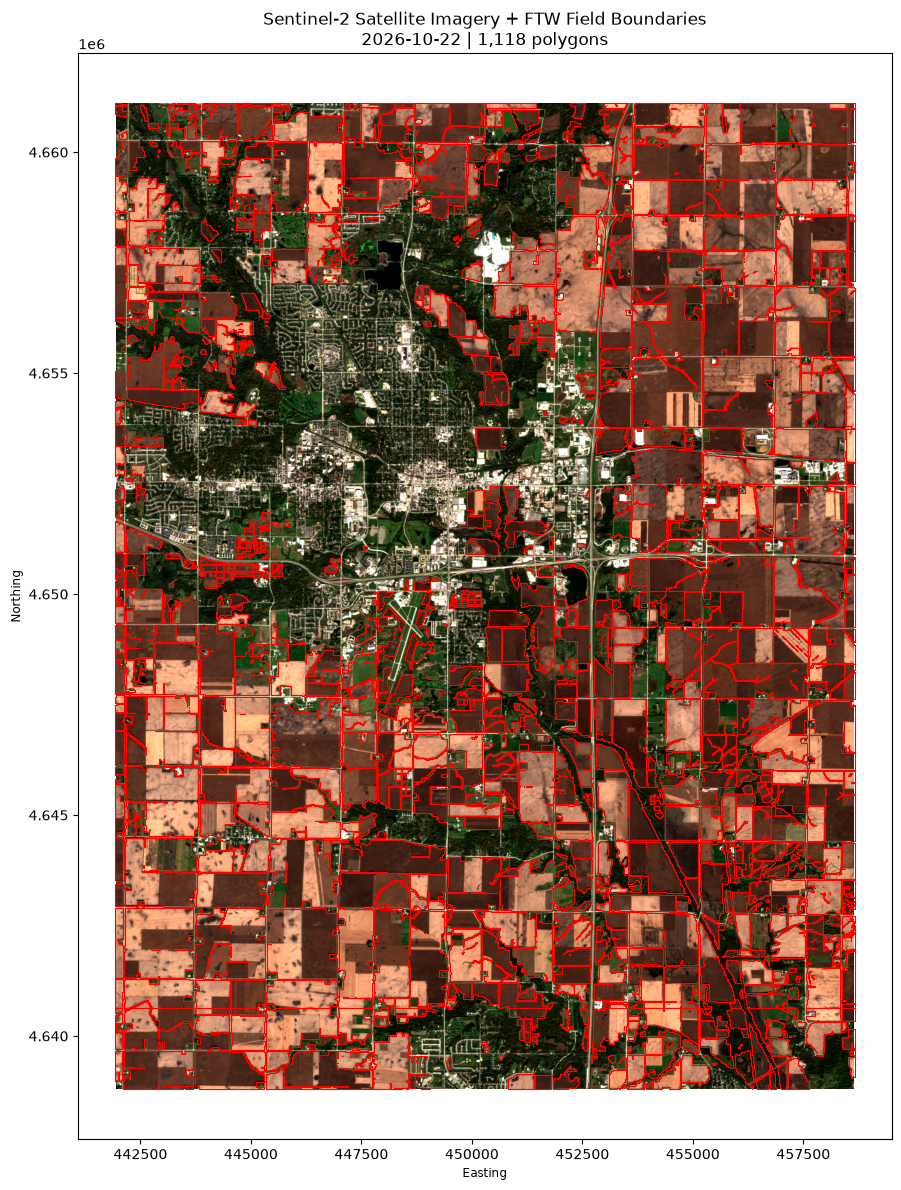

Saved: C:\Users\ABCOM\ftw-baselines\ftw_output\satellite_fields_overlay.png


In [18]:
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt

from rasterio.windows import from_bounds
from rasterio.warp import transform_bounds
from rasterio.plot import reshape_as_image
from shapely import wkb
from pathlib import Path

# Download/read the satellite bands directly from the catalog
red_url = item.assets["B04"].href
green_url = item.assets["B03"].href
blue_url = item.assets["B02"].href

with rasterio.open(red_url) as src:
    image_crs = src.crs
    crop_bounds = transform_bounds(
        "EPSG:4326", src.crs, *bbox
    )
    window = from_bounds(*crop_bounds, transform=src.transform)
    red = src.read(1, window=window).astype("float32")
    transform = src.window_transform(window)

with rasterio.open(green_url) as src:
    green = src.read(1, window=window).astype("float32")

with rasterio.open(blue_url) as src:
    blue = src.read(1, window=window).astype("float32")

rgb = np.stack([red, green, blue], axis=-1)

# Robust contrast stretch for natural-colour display
valid = np.isfinite(rgb).all(axis=-1) & (rgb.sum(axis=-1) > 0)
if not valid.any():
    raise RuntimeError("The selected scene has no valid pixels in this area.")

low, high = np.percentile(rgb[valid], [2, 98])
rgb = np.clip((rgb - low) / max(high - low, 1), 0, 1)
rgb[~valid] = 0

# Load your FTW polygon output
out = Path(r"C:\Users\ABCOM\ftw-baselines\ftw_output")
df = pd.read_parquet(out / "polygons.parquet")

df["geometry"] = df["geometry"].apply(
    lambda g: wkb.loads(bytes(g)) if g is not None else None
)

polygons = gpd.GeoDataFrame(
    df, geometry="geometry", crs=image_crs
)

# Plot satellite imagery and polygon boundaries
fig, ax = plt.subplots(figsize=(16, 12))

left = transform.c
top = transform.f
right = left + rgb.shape[1] * transform.a
bottom = top + rgb.shape[0] * transform.e

ax.imshow(
    rgb,
    extent=[left, right, bottom, top],
    origin="upper"
)

polygons.boundary.plot(
    ax=ax,
    color="red",
    linewidth=0.8
)

ax.set_title(
    f"Sentinel-2 Satellite Imagery + FTW Field Boundaries\n"
    f"{item.datetime.date()} | {len(polygons):,} polygons"
)
ax.set_xlabel("Easting")
ax.set_ylabel("Northing")

plt.tight_layout()
plt.savefig(out / "satellite_fields_overlay.png", dpi=300)
plt.show()

print("Saved:", out / "satellite_fields_overlay.png")

In [15]:
# import rasterio
# import numpy as np
# import matplotlib.pyplot as plt
# from pathlib import Path

# # Input file path
# input_file = Path(
#     r"C:\Users\ABCOM\ftw-baselines\ftw_output\inference_data.tif"
# )

# # Read the raster
# with rasterio.open(input_file) as src:
#     image = src.read()
#     print("Image dimensions (bands, height, width):", image.shape)
#     print("Number of bands:", src.count)
#     print("Coordinate system:", src.crs)
#     print("Bounds:", src.bounds)
#     print("Data type:", src.dtypes)

# # Display the image
# if image.shape[0] >= 3:
#     rgb = np.moveaxis(image[:3], 0, -1)

#     # Normalize values for visualization
#     rgb = rgb.astype(np.float32)
#     for i in range(3):
#         band = rgb[:, :, i]
#         low, high = np.nanpercentile(band, [2, 98])
#         if high > low:
#             rgb[:, :, i] = np.clip((band - low) / (high - low), 0, 1)

#     plt.figure(figsize=(12, 10))
#     plt.imshow(rgb)
#     plt.title("FTW Input Raster — inference_data.tif")
#     plt.axis("off")
#     plt.show()
# else:
#     plt.figure(figsize=(12, 10))
#     plt.imshow(image[0], cmap="gray")
#     plt.title("FTW Input Raster — Band 1")
#     plt.axis("off")
#     plt.show()

In [16]:
# import rasterio
# import numpy as np
# import matplotlib.pyplot as plt

# output_file = r"C:\Users\ABCOM\ftw-baselines\ftw_output\inference_output.tif"

# with rasterio.open(output_file) as src:
#     prediction = src.read()

#     print("Shape:", prediction.shape)
#     print("Bands:", src.count)
#     print("Data type:", src.dtypes)
#     print("CRS:", src.crs)
#     print("Unique values:", np.unique(prediction[0])[:30])

# plt.figure(figsize=(12, 8))
# plt.imshow(prediction[0], cmap="viridis")
# plt.title("FTW Inference Output")
# plt.colorbar()
# plt.axis("off")
# plt.show()

In [1]:
import math
import subprocess
from pathlib import Path

# Your existing FTW project
PROJECT_DIR = Path(r"C:\Users\ABCOM\ftw-baselines")

# Replace these with the actual GPS coordinates from your browser
latitude = 42.099946
longitude = -93.681996

# Create a bounding box around the location
radius_m = 2000

lat_delta = radius_m / 111320
lon_delta = radius_m / (
    111320 * math.cos(math.radians(latitude))
)

min_lon = longitude - lon_delta
max_lon = longitude + lon_delta
min_lat = latitude - lat_delta
max_lat = latitude + lat_delta

bbox = (
    f"{min_lon},{min_lat},{max_lon},{max_lat}"
)

print("GPS latitude:", latitude)
print("GPS longitude:", longitude)
print("Bounding box:", bbox)

# Store the FTW output separately
OUTPUT_DIR = PROJECT_DIR / "gps_ftw_output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Run FTW inference
cmd = [
    "uv", "run", "ftw", "inference", "all",
    "--bbox", bbox,
    "--year", "2025",
    "--out", str(OUTPUT_DIR),
    "--model", "FTW_PRUE_EFNET_B5_CCBY",
    "--gpu", "-1",
    "--cloud_cover_max", "50",
    "--buffer_days", "45",
    "--overwrite",
]

print("\nStarting FTW inference...")
print("Output directory:", OUTPUT_DIR)

result = subprocess.run(
    cmd,
    cwd=str(PROJECT_DIR),
    capture_output=True,
    text=True,
    timeout=None,
)

print(result.stdout)

if result.returncode != 0:
    print("\nFTW ERROR:")
    print(result.stderr)
else:
    print("\nFTW inference completed successfully.")

GPS latitude: 42.099946
GPS longitude: -93.681996
Bounding box: -93.70621000699016,42.081979776500184,-93.65778199300983,42.11791222349982

Starting FTW inference...
Output directory: C:\Users\ABCOM\ftw-baselines\gps_ftw_output
Processing version 5.11 unknown or untested (< 3.0 or >= 4.0). Inference quality might decrease.
Rescaling data to processing version 3.0 from processing version 5.11.
Writing output

[                                        ] | 0% Completed | 1.23 ms
[############                            ] | 32% Completed | 103.27 ms
[############                            ] | 32% Completed | 204.03 ms
[############                            ] | 32% Completed | 304.65 ms
[############                            ] | 32% Completed | 405.16 ms
[############                            ] | 32% Completed | 507.27 ms
[############                            ] | 32% Completed | 608.02 ms
[############                            ] | 32% Completed | 708.70 ms
[############          

In [2]:
from pathlib import Path
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
import numpy as np

# Existing FTW output directory
OUTPUT_DIR = Path(
    r"C:\Users\ABCOM\ftw-baselines\gps_ftw_output"
)

POLYGON_FILE = OUTPUT_DIR / "polygons.parquet"
PREDICTION_FILE = OUTPUT_DIR / "inference_output.tif"
IMAGE_FILE = OUTPUT_DIR / "inference_data.tif"

print("Polygon file exists:", POLYGON_FILE.exists())
print("Prediction raster exists:", PREDICTION_FILE.exists())
print("Satellite image exists:", IMAGE_FILE.exists())

Polygon file exists: True
Prediction raster exists: True
Satellite image exists: True


Polygon file exists: True
Prediction raster exists: True
Satellite image exists: True


In [3]:
gdf = gpd.read_parquet(POLYGON_FILE)

print("Number of polygon features:", len(gdf))
print("Coordinate reference system:", gdf.crs)
print("\nAvailable columns:")
print(gdf.columns.tolist())

display(gdf.head())

Number of polygon features: 88
Coordinate reference system: {"$schema": "https://proj.org/schemas/v0.7/projjson.schema.json", "type": "ProjectedCRS", "name": "WGS 84 / UTM zone 15N", "base_crs": {"type": "GeographicCRS", "name": "WGS 84", "datum_ensemble": {"name": "World Geodetic System 1984 ensemble", "members": [{"name": "World Geodetic System 1984 (Transit)"}, {"name": "World Geodetic System 1984 (G730)"}, {"name": "World Geodetic System 1984 (G873)"}, {"name": "World Geodetic System 1984 (G1150)"}, {"name": "World Geodetic System 1984 (G1674)"}, {"name": "World Geodetic System 1984 (G1762)"}, {"name": "World Geodetic System 1984 (G2139)"}, {"name": "World Geodetic System 1984 (G2296)"}], "ellipsoid": {"name": "WGS 84", "semi_major_axis": 6378137, "inverse_flattening": 298.257223563}, "accuracy": "2.0", "id": {"authority": "EPSG", "code": 6326}}, "coordinate_system": {"subtype": "ellipsoidal", "axis": [{"name": "Geodetic latitude", "abbreviation": "Lat", "direction": "north", "unit

,id,geometry,metrics:perimeter,metrics:area
0,1,"POLYGON ((445430 4663110, 445430 4663090, 4454...",240.0,2500.0
1,2,"POLYGON ((442960 4663110, 442960 4663100, 4429...",460.0,6000.0
2,3,"POLYGON ((445400 4663100, 445400 4663010, 4454...",400.0,5900.0
3,4,"POLYGON ((441580 4663100, 441580 4663020, 4415...",700.0,8800.0
4,5,"POLYGON ((441650 4662940, 441650 4662920, 4416...",120.0,500.0


In [25]:
with rasterio.open(IMAGE_FILE) as src:
    satellite_data = src.read()
    image_transform = src.transform
    image_crs = src.crs

    print("Image dimensions:", src.width, "x", src.height)
    print("Number of bands:", src.count)
    print("Image CRS:", image_crs)
    print("Band data types:", src.dtypes)

print("Loaded satellite image successfully.")

Image dimensions: 405 x 403
Number of bands: 8
Image CRS: EPSG:32615
Band data types: ('uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16')
Loaded satellite image successfully.


In [21]:
# Move the band axis to the end for plotting.
image = np.moveaxis(satellite_data, 0, -1)

plt.figure(figsize=(12, 10))

if image.shape[-1] >= 3:
    # Display the first three bands as an RGB-style image.
    rgb = image[:, :, :3].astype(float)

    # Stretch the values for visualization.
    lower = np.nanpercentile(rgb, 2)
    upper = np.nanpercentile(rgb, 98)

    if upper > lower:
        rgb = np.clip((rgb - lower) / (upper - lower), 0, 1)

    plt.imshow(rgb)
else:
    plt.imshow(image[:, :, 0], cmap="gray")

plt.title("FTW Input Satellite Image")
plt.axis("off")
plt.show()

NameError: name 'satellite_data' is not defined

In [22]:
# with rasterio.open(PREDICTION_FILE) as src:
#     prediction = src.read(1)

#     print("Prediction dimensions:", src.width, "x", src.height)
#     print("Prediction CRS:", src.crs)
#     print("Prediction data type:", src.dtypes[0])
#     print("Minimum value:", np.nanmin(prediction))
#     print("Maximum value:", np.nanmax(prediction))
#     print("Unique values:", np.unique(prediction)[:30])

# plt.figure(figsize=(12, 10))
# plt.imshow(prediction, cmap="gray")
# plt.title("FTW Inference Output")
# plt.colorbar(label="Pixel value")
# plt.axis("off")
# plt.show()

In [23]:
# print("Total features:", len(gdf))
# print("Geometry types:")
# print(gdf.geometry.geom_type.value_counts())

# fig, ax = plt.subplots(figsize=(12, 10))

# gdf.plot(
#     ax=ax,
#     facecolor="none",
#     edgecolor="red",
#     linewidth=1
# )

# ax.set_title("FTW Detected Farmland Polygons")
# ax.set_xlabel("X coordinate")
# ax.set_ylabel("Y coordinate")

# plt.show()

NameError: name 'satellite_data' is not defined

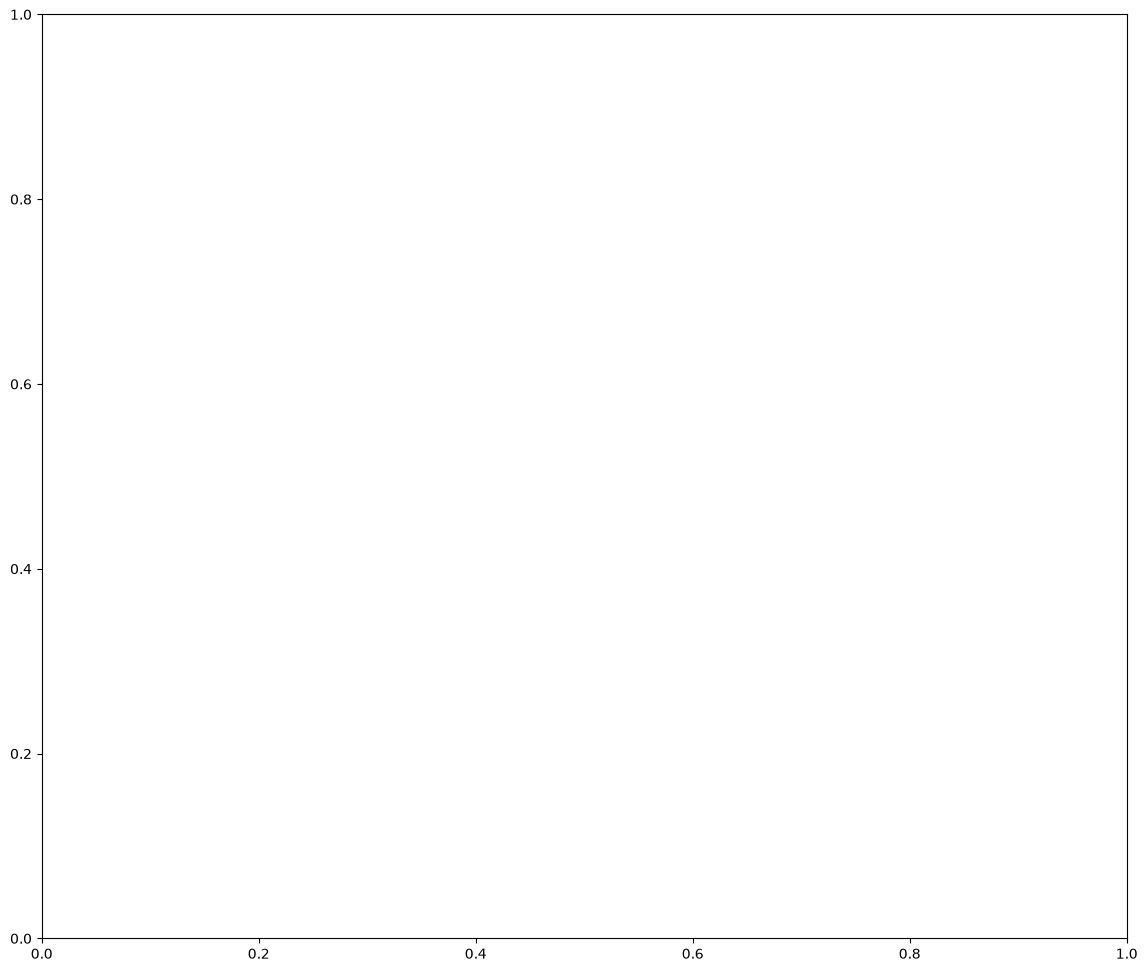

In [24]:
with rasterio.open(IMAGE_FILE) as src:
    image_crs = src.crs
    image_bounds = src.bounds

if image_crs is None:
    raise ValueError("The satellite image has no CRS.")

if gdf.crs is None:
    raise ValueError("The polygon file has no CRS.")

# Transform polygons into the image's coordinate system.
gdf_image_crs = gdf.to_crs(image_crs)

fig, ax = plt.subplots(figsize=(14, 12))

# Show the satellite image.
if satellite_data.shape[0] >= 3:
    rgb = np.moveaxis(satellite_data[:3], 0, -1).astype(float)

    lower = np.nanpercentile(rgb, 2)
    upper = np.nanpercentile(rgb, 98)

    if upper > lower:
        rgb = np.clip((rgb - lower) / (upper - lower), 0, 1)

    ax.imshow(
        rgb,
        extent=[
            image_bounds.left,
            image_bounds.right,
            image_bounds.bottom,
            image_bounds.top
        ]
    )
else:
    ax.imshow(
        satellite_data[0],
        cmap="gray",
        extent=[
            image_bounds.left,
            image_bounds.right,
            image_bounds.bottom,
            image_bounds.top
        ]
    )

# Overlay field boundaries.
gdf_image_crs.boundary.plot(
    ax=ax,
    edgecolor="red",
    linewidth=1
)

ax.set_title("Satellite Image with FTW Field Boundaries")
ax.set_xlabel("X coordinate")
ax.set_ylabel("Y coordinate")

plt.show()

In [25]:
# Replace these example values with your actual browser coordinates.
GPS_LATITUDE = 42.099946
GPS_LONGITUDE = -93.681996

In [26]:
import geopandas as gpd
from shapely.geometry import Point
from pathlib import Path

OUTPUT_DIR = Path(r"C:\Users\ABCOM\ftw-baselines\gps_ftw_output")
POLYGON_FILE = OUTPUT_DIR / "polygons.parquet"

# Load the polygons generated by FTW
gdf = gpd.read_parquet(POLYGON_FILE)

print("Total detected polygons:", len(gdf))
# print("Polygon CRS:", gdf.crs)

if gdf.crs is None:
    print("ERROR: The polygon CRS is missing.")
else:
    # Convert the GPS point from latitude/longitude to the polygon CRS
    gps_point = gpd.GeoDataFrame(
        geometry=[Point(GPS_LONGITUDE, GPS_LATITUDE)],
        crs="EPSG:4326"
    ).to_crs(gdf.crs)

    point = gps_point.geometry.iloc[0]

    # Find the polygon that contains or touches the GPS point
    matches = gdf[
        gdf.geometry.notna()
        & ~gdf.geometry.is_empty
        & gdf.geometry.intersects(point)
    ].copy()

    print("Polygons matching GPS point:", len(matches))

    if len(matches) > 0:
        display(matches)
    else:
        print("No detected polygon contains this GPS point.")

Total detected polygons: 88
Polygons matching GPS point: 1


,metrics:perimeter,id,metrics:area,geometry
44,7300.0,45,649800.0,"POLYGON ((443380 4661860, 443380 4661730, 4431..."


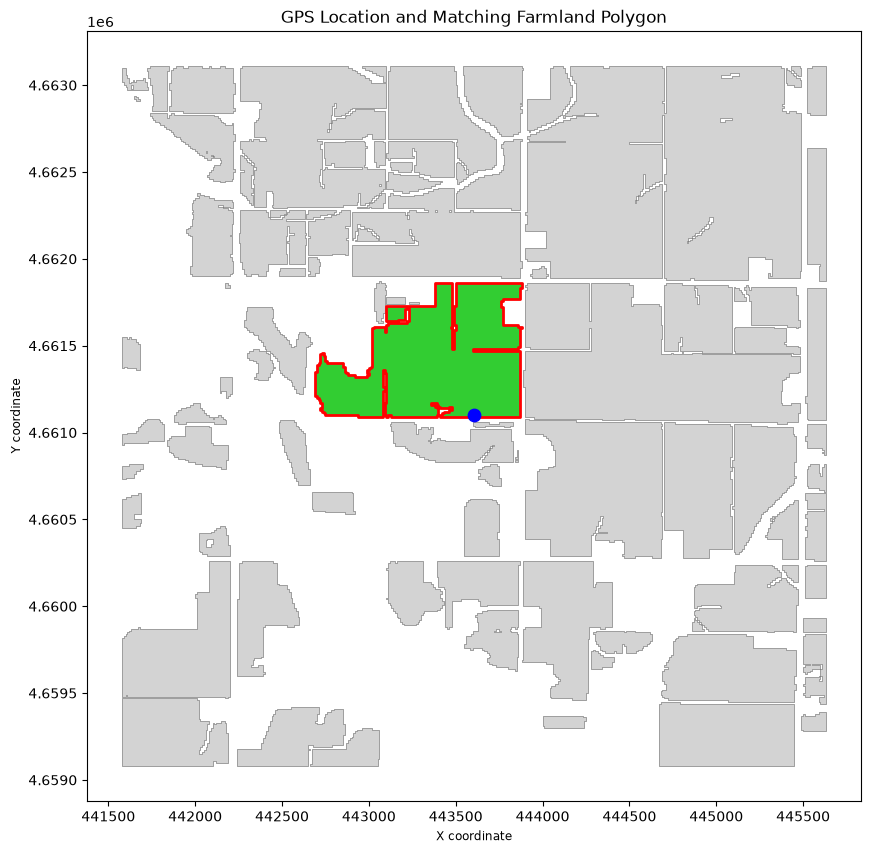

In [27]:
import matplotlib.pyplot as plt

if len(matches) > 0:
    fig, ax = plt.subplots(figsize=(10, 10))

    # Plot all detected polygons in light grey
    gdf.plot(
        ax=ax,
        facecolor="lightgrey",
        edgecolor="grey",
        linewidth=0.5
    )

    # Highlight the polygon matching your GPS point
    matches.plot(
        ax=ax,
        facecolor="limegreen",
        edgecolor="red",
        linewidth=2
    )

    # Mark the GPS location
    gps_point.plot(
        ax=ax,
        color="blue",
        markersize=80
    )

    ax.set_title("GPS Location and Matching Farmland Polygon")
    ax.set_xlabel("X coordinate")
    ax.set_ylabel("Y coordinate")

    plt.show()
else:
    print("No matching polygon to display.")